# SpaceLaunch Analytics — Exploratory Data Analysis

**Project:** ETL + EDA Pipeline  
**Dataset:** Validated historical rocket-launch records (2020–2025)

This notebook answers the six research questions in the project's *Data Visualization Plan*.
It reads the validated `launches` table from SQLite. It does not call the API or modify the database.

> **Expected location:** Save this notebook inside the project's `notebooks/` folder.  
> Expected database: `data/database/launches.db`  
> Expected validation report: `data/processed/validation_report.json`

## 1. Import libraries and configure paths

The notebook uses:
- **pandas** for data analysis
- **Plotly** for interactive charts
- **sqlite3** to read the SQLite database
- **matplotlib** only if needed for supplementary static output

In [1]:
from pathlib import Path
import sqlite3
import json
import warnings

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# This notebook is expected to be inside the project's "notebooks" folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DB_PATH = PROJECT_ROOT / "data" / "database" / "launches.db"
VALIDATION_REPORT_PATH = PROJECT_ROOT / "data" / "processed" / "validation_report.json"
REJECTED_RECORDS_PATH = PROJECT_ROOT / "data" / "processed" / "rejected_records.json"

print("Project folder:", PROJECT_ROOT)
print("Database found:", DB_PATH.exists())
print("Validation report found:", VALIDATION_REPORT_PATH.exists())

Project folder: E:\Before window\AHSAN\PAI\spaceLaunch_Analylics
Database found: True
Validation report found: True


## 2. Load validated data from SQLite

The database schema follows `load.py`. We read all rows from the `launches` table into a pandas DataFrame.

In [2]:
if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}\n"
        "Make sure you have run src/load.py and that this notebook is inside the notebooks folder."
    )

with sqlite3.connect(DB_PATH) as connection:
    df = pd.read_sql_query("SELECT * FROM launches", connection)

if df.empty:
    raise ValueError("The launches table is empty. Run the ETL pipeline before EDA.")

# Ensure fields have the expected data types.
df["launch_datetime"] = pd.to_datetime(df["launch_datetime"], errors="coerce", utc=True)
df["launch_year"] = pd.to_numeric(df["launch_year"], errors="coerce").astype("Int64")
df["launch_month"] = pd.to_numeric(df["launch_month"], errors="coerce").astype("Int64")

for column in ["launch_name", "provider", "rocket", "launch_location", "country", "status"]:
    if column in df.columns:
        df[column] = df[column].fillna("Unknown").astype(str).str.strip()
        df.loc[df[column].eq(""), column] = "Unknown"

print(f"Validated launch records loaded: {len(df):,}")
display(df.head())

Validated launch records loaded: 10


,launch_id,launch_name,launch_datetime,launch_year,launch_month,provider,rocket,launch_location,country,status
0,fb6d9dd6-2087-40b7-b3ca-c807b5b2be43,Long March 7A | Shijian 29 A-B,2025-12-30 22:40:00+00:00,2025,12,China Aerospace Science and Technology Corpora...,Long March 7A,201,China,Launch Successful
1,53aad862-af92-44b5-91ef-70e92a079ba4,Long March 4B | Tianhui 7,2025-12-30 04:12:00+00:00,2025,12,China Aerospace Science and Technology Corpora...,Long March 4B,Launch Area 94 (SLS-2 / 603),China,Launch Successful
2,43cfdc96-8481-446f-ace5-ddc5ed60fb14,Soyuz 2.1b/Fregat-M | AIST-2T 01 & 02,2025-12-28 13:18:05+00:00,2025,12,Russian Federal Space Agency (ROSCOSMOS),Soyuz 2.1b/Fregat-M,Cosmodrome Site 1S,Russia,Launch Successful
3,9d69b85a-940d-4c1a-be75-6449d3b2a836,Long March 3B/E | Fengyun-4C,2025-12-26 16:07:00+00:00,2025,12,China Aerospace Science and Technology Corpora...,Long March 3B/E,Launch Complex 2 (LC-2),China,Launch Successful
4,f4909efe-4764-43fa-9e4a-07e479af1ba7,Long March 8A | SatNet LEO Group 17,2025-12-25 23:26:00+00:00,2025,12,China Aerospace Science and Technology Corpora...,Long March 8A,Commercial LC-1,China,Launch Successful


## 3. Dataset overview

A quick overview of the dataset, its date coverage, and the number of distinct providers, rockets, and launch locations.

In [3]:
overview = pd.DataFrame({
    "Metric": [
        "Total validated launches",
        "First recorded launch date",
        "Last recorded launch date",
        "Distinct providers",
        "Distinct rocket configurations",
        "Distinct launch locations",
        "Countries represented"
    ],
    "Value": [
        f"{len(df):,}",
        df["launch_datetime"].min().strftime("%Y-%m-%d") if df["launch_datetime"].notna().any() else "Not available",
        df["launch_datetime"].max().strftime("%Y-%m-%d") if df["launch_datetime"].notna().any() else "Not available",
        df["provider"].nunique(),
        df["rocket"].nunique(),
        df["launch_location"].nunique(),
        df["country"].nunique()
    ]
})

display(overview)
display(df.describe(include="all").T)

,Metric,Value
0,Total validated launches,10
1,First recorded launch date,2025-12-22
2,Last recorded launch date,2025-12-30
3,Distinct providers,5
4,Distinct rocket configurations,10
5,Distinct launch locations,10
6,Countries represented,5


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
launch_id,10,10,fb6d9dd6-2087-40b7-b3ca-c807b5b2be43,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
launch_name,10,10,Long March 7A | Shijian 29 A-B,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
launch_datetime,10,NaN,NaN,NaN,2025-12-26 00:38:24.500000+00:00,2025-12-22 01:51:30+00:00,2025-12-23 08:21:22.500000+00:00,2025-12-25 18:48:30+00:00,2025-12-28 02:00:18.750000+00:00,2025-12-30 22:40:00+00:00,NaN
launch_year,10.0,<NA>,<NA>,<NA>,2025.0,2025.0,2025.0,2025.0,2025.0,2025.0,0.0
launch_month,10.0,<NA>,<NA>,<NA>,12.0,12.0,12.0,12.0,12.0,12.0,0.0
provider,10,5,China Aerospace Science and Technology Corpora...,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rocket,10,10,Long March 7A,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
launch_location,10,10,201,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,10,5,China,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,10,2,Launch Successful,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Research Question 1 — Launch activity over time

**Question:** How has the number of recorded launches changed over time, by year and month?

The monthly line chart shows rises and dips over time. The yearly bar chart provides a high-level comparison.

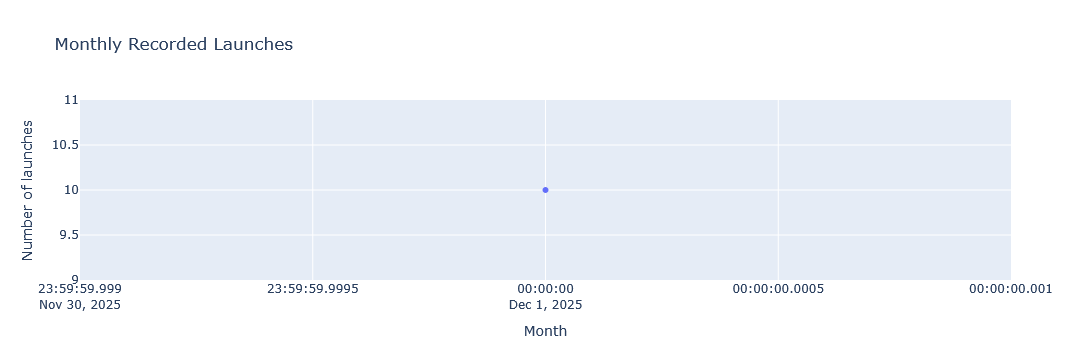

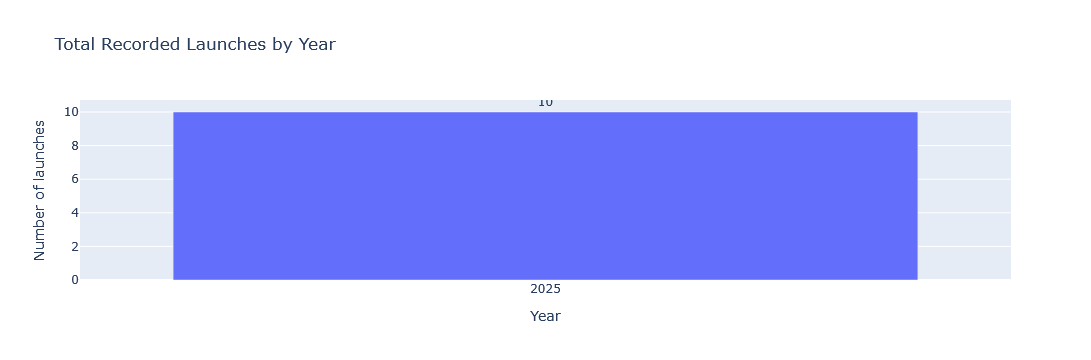

In [4]:
# Monthly launch counts, ordered chronologically.
monthly = (
    df.dropna(subset=["launch_datetime"])
      .assign(month_start=lambda x: x["launch_datetime"].dt.to_period("M").dt.to_timestamp())
      .groupby("month_start")
      .size()
      .reset_index(name="launches")
      .sort_values("month_start")
)

fig = px.line(
    monthly,
    x="month_start",
    y="launches",
    markers=True,
    title="Monthly Recorded Launches",
    labels={"month_start": "Month", "launches": "Number of launches"}
)
fig.update_layout(hovermode="x unified")
fig.show()

yearly = (
    df.dropna(subset=["launch_year"])
      .groupby("launch_year")
      .size()
      .reset_index(name="launches")
      .sort_values("launch_year")
)
yearly["launch_year"] = yearly["launch_year"].astype(str)

fig = px.bar(
    yearly,
    x="launch_year",
    y="launches",
    text="launches",
    title="Total Recorded Launches by Year",
    labels={"launch_year": "Year", "launches": "Number of launches"}
)
fig.update_traces(textposition="outside")
fig.show()

# Research Question 2 — Most frequent providers, rockets, and locations

**Question:** Which launch service providers, rocket configurations, and launch locations appear most frequently?

The charts show the top 10 in each category. Remaining categories are combined into **Other** when there are more than 10.

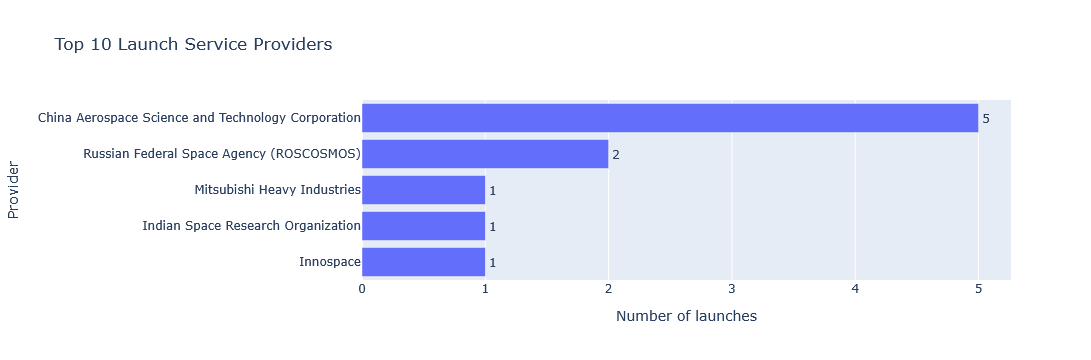

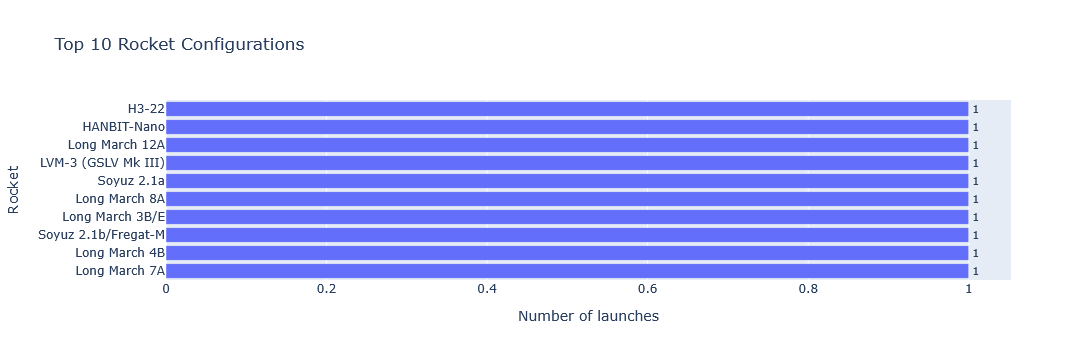

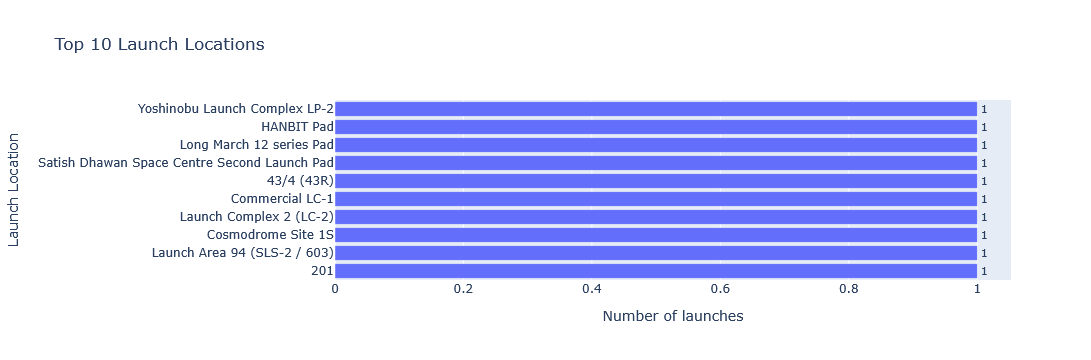

In [5]:
def top_ten_with_other(data, column):
    counts = data[column].replace("", "Unknown").fillna("Unknown").value_counts()
    top = counts.head(10)
    if len(counts) > 10:
        top.loc["Other"] = counts.iloc[10:].sum()
    return top.sort_values(ascending=True).rename_axis(column).reset_index(name="launches")

for column, title in [
    ("provider", "Top 10 Launch Service Providers"),
    ("rocket", "Top 10 Rocket Configurations"),
    ("launch_location", "Top 10 Launch Locations")
]:
    chart_data = top_ten_with_other(df, column)
    fig = px.bar(
        chart_data,
        x="launches",
        y=column,
        orientation="h",
        text="launches",
        title=title,
        labels={column: column.replace("_", " ").title(), "launches": "Number of launches"}
    )
    fig.update_traces(textposition="outside")
    fig.show()

# Research Question 3 — Launch outcomes across providers and years

**Question:** How do recorded launch outcomes vary across providers and years?

These are 100% stacked bar charts. Each bar represents the outcome distribution within one provider or year.
Only records with a known status are included. Non-final statuses (for example, To Be Confirmed or On Hold) remain visible as **Other known outcomes** rather than being treated as failures.

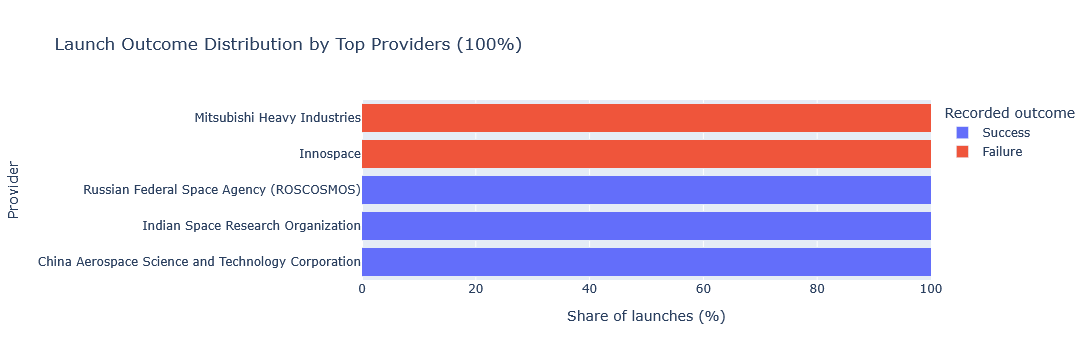

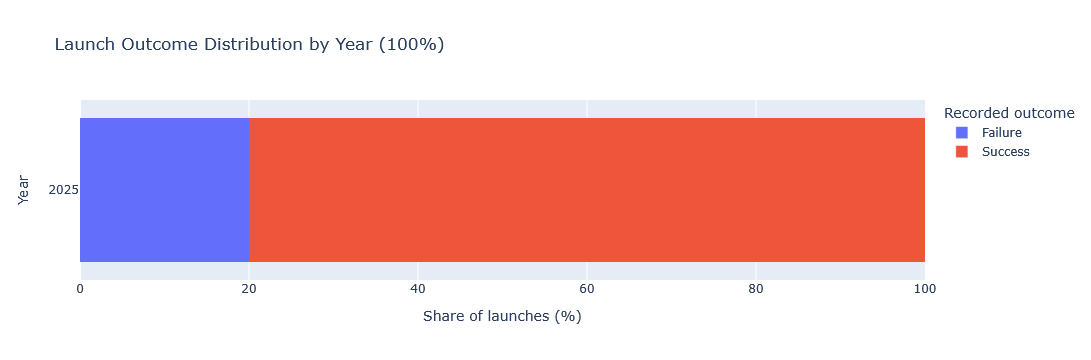

In [6]:
def outcome_group(status):
    value = str(status).strip().casefold()
    if value == "launch successful":
        return "Success"
    if value == "launch failure":
        return "Failure"
    if value in {"launch was a partial failure", "launch partial failure"}:
        return "Partial failure"
    return "Other known outcomes"

outcomes = df.copy()
outcomes["outcome_group"] = outcomes["status"].apply(outcome_group)
outcomes = outcomes[outcomes["status"].ne("Unknown")]

# Show the providers with the most records so the chart remains readable.
top_providers = outcomes["provider"].value_counts().head(10).index
provider_outcomes = outcomes[outcomes["provider"].isin(top_providers)]

provider_mix = (
    provider_outcomes.groupby(["provider", "outcome_group"])
    .size().rename("launches").reset_index()
)
provider_mix["provider_total"] = provider_mix.groupby("provider")["launches"].transform("sum")
provider_mix["share"] = provider_mix["launches"] / provider_mix["provider_total"] * 100

fig = px.bar(
    provider_mix,
    x="share",
    y="provider",
    color="outcome_group",
    orientation="h",
    barmode="stack",
    title="Launch Outcome Distribution by Top Providers (100%)",
    labels={"share": "Share of launches (%)", "provider": "Provider", "outcome_group": "Recorded outcome"},
    custom_data=["launches", "provider_total"]
)
fig.update_traces(
    hovertemplate="%{y}<br>Outcome: %{fullData.name}<br>Share: %{x:.1f}%<br>Count: %{customdata[0]} of %{customdata[1]}<extra></extra>"
)
fig.update_layout(xaxis_range=[0, 100])
fig.show()

year_outcomes = outcomes.dropna(subset=["launch_year"]).copy()
year_outcomes["launch_year"] = year_outcomes["launch_year"].astype(str)
year_mix = (
    year_outcomes.groupby(["launch_year", "outcome_group"])
    .size().rename("launches").reset_index()
)
year_mix["year_total"] = year_mix.groupby("launch_year")["launches"].transform("sum")
year_mix["share"] = year_mix["launches"] / year_mix["year_total"] * 100

fig = px.bar(
    year_mix,
    x="share",
    y="launch_year",
    color="outcome_group",
    orientation="h",
    barmode="stack",
    title="Launch Outcome Distribution by Year (100%)",
    labels={"share": "Share of launches (%)", "launch_year": "Year", "outcome_group": "Recorded outcome"},
    custom_data=["launches", "year_total"]
)
fig.update_traces(
    hovertemplate="%{y}<br>Outcome: %{fullData.name}<br>Share: %{x:.1f}%<br>Count: %{customdata[0]} of %{customdata[1]}<extra></extra>"
)
fig.update_layout(xaxis_range=[0, 100])
fig.show()

# Research Question 4 — Year-over-year changes and monthly patterns

**Question:** What year-over-year changes and monthly patterns can be observed in launch activity?

The heatmap compares each calendar month across years. The second chart shows the percentage change in annual launch totals compared with the previous year. The first year has no previous year for comparison.

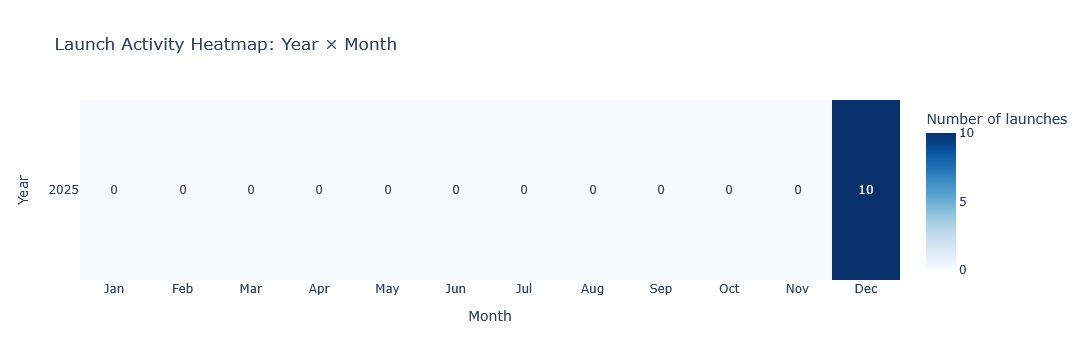

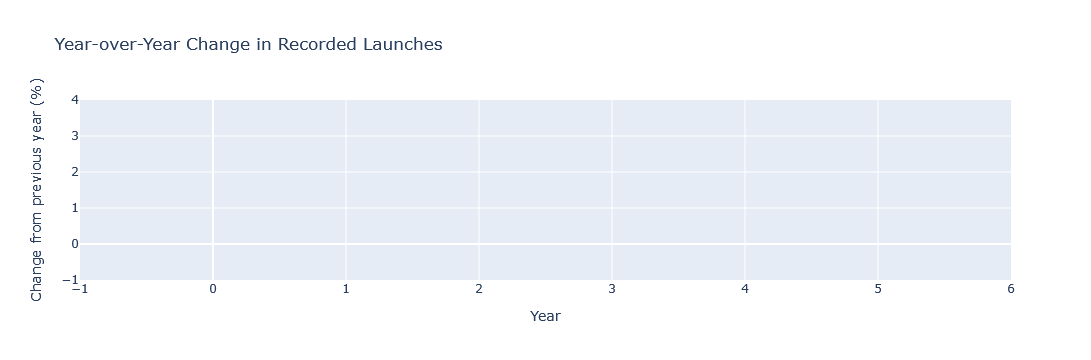

,launch_year,launches,yoy_change_pct
0,2025,10,NaN


In [7]:
year_month = (
    df.dropna(subset=["launch_year", "launch_month"])
      .groupby(["launch_year", "launch_month"])
      .size()
      .rename("launches")
      .reset_index()
)

heatmap_data = year_month.pivot(
    index="launch_year", columns="launch_month", values="launches"
).reindex(columns=range(1, 13)).fillna(0)

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig = px.imshow(
    heatmap_data,
    labels={"x": "Month", "y": "Year", "color": "Number of launches"},
    x=month_names,
    y=heatmap_data.index.astype(str),
    text_auto=True,
    aspect="auto",
    title="Launch Activity Heatmap: Year × Month",
    color_continuous_scale="Blues"
)
fig.show()

annual_counts = (
    df.dropna(subset=["launch_year"])
      .groupby("launch_year").size()
      .rename("launches").reset_index()
      .sort_values("launch_year")
)
annual_counts["yoy_change_pct"] = annual_counts["launches"].pct_change() * 100
yoy = annual_counts.dropna(subset=["yoy_change_pct"]).copy()
yoy["direction"] = np.where(yoy["yoy_change_pct"] >= 0, "Increase", "Decrease")
yoy["launch_year"] = yoy["launch_year"].astype(str)

fig = px.bar(
    yoy,
    x="launch_year",
    y="yoy_change_pct",
    color="direction",
    text=yoy["yoy_change_pct"].map(lambda value: f"{value:+.1f}%"),
    title="Year-over-Year Change in Recorded Launches",
    labels={"launch_year": "Year", "yoy_change_pct": "Change from previous year (%)", "direction": "Change"}
)
fig.add_hline(y=0, line_dash="dash", line_color="gray")
fig.update_traces(textposition="outside")
fig.show()

display(annual_counts)

# Research Question 5 — Data quality of source records

**Question:** What proportion of source records contain missing, inconsistent, invalid, or duplicate data?

The validation report is produced by the validation stage, not stored in the `launches` table. This section reads `validation_report.json` if it exists. The notebook will show the report's contents first so that its actual field names and counts remain transparent.

The funnel uses: **Total extracted → after duplicate removal → valid → rejected**.

In [8]:
def load_json_if_available(path):
    if path.exists():
        with open(path, "r", encoding="utf-8") as file:
            return json.load(file)
    return None

validation_report = load_json_if_available(VALIDATION_REPORT_PATH)

if validation_report is None:
    print("Validation report not found:", VALIDATION_REPORT_PATH)
    print("Q5 cannot be fully calculated from the SQLite table alone.")
    print("Place data/processed/validation_report.json in the expected location and rerun this section.")
else:
    print("Validation report loaded. Raw report structure:")
    print(json.dumps(validation_report, indent=4, ensure_ascii=False))

Validation report loaded. Raw report structure:
{
    "total_records": 10,
    "valid_records": 10,
    "rejected_records": 0,
    "duplicate_records": 0,
    "missing_values": 0,
    "invalid_records": 0,
    "reject_rate": 0.0,
    "expected_records": 10,
    "count_matches_expected": true,
    "status": "completed"
}


### Q5A. Validation funnel and KPI summary

Because validation-report key names can differ between implementations, the following cell searches common key names. If a value cannot be identified, it displays `Not available` rather than guessing.

,Metric,Count
0,Total extracted,10
1,After duplicate removal,10
2,Valid records,10
3,Rejected records,0
4,Duplicate records,0


,KPI,Value
0,Valid records (%),100.00%
1,Rejected records (%),0.00%
2,Duplicate records (%),0.00%


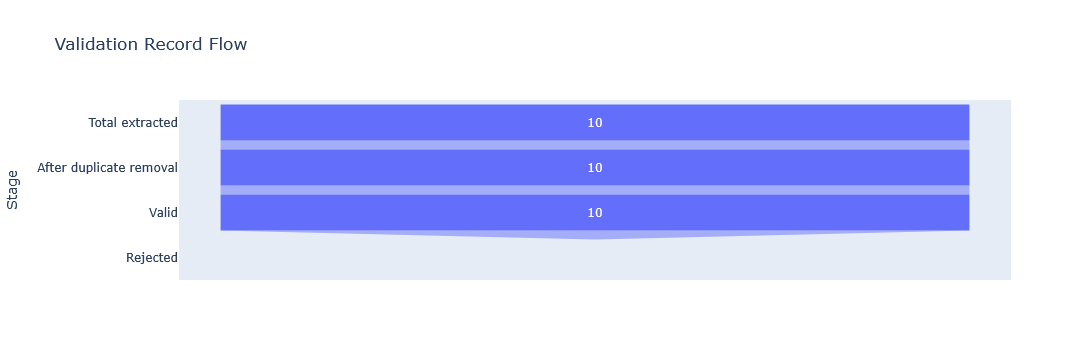

In [9]:
def find_value(obj, candidate_names):
    candidate_names = {name.casefold() for name in candidate_names}
    if isinstance(obj, dict):
        for key, value in obj.items():
            if str(key).casefold() in candidate_names and isinstance(value, (int, float)):
                return value
        for value in obj.values():
            found = find_value(value, candidate_names)
            if found is not None:
                return found
    elif isinstance(obj, list):
        for value in obj:
            found = find_value(value, candidate_names)
            if found is not None:
                return found
    return None

if validation_report is not None:
    total_extracted = find_value(validation_report, [
        "total_records", "total_input_records", "total_extracted", "input_records"
    ])
    duplicates = find_value(validation_report, [
        "duplicate_records", "duplicates", "duplicate_count"
    ])
    valid_count = find_value(validation_report, [
        "valid_records", "valid_count", "accepted_records"
    ])
    rejected_count = find_value(validation_report, [
        "rejected_records", "rejected_count", "invalid_records"
    ])
    after_dedup = (
        total_extracted - duplicates
        if total_extracted is not None and duplicates is not None
        else None
    )

    quality_metrics = pd.DataFrame({
        "Metric": ["Total extracted", "After duplicate removal", "Valid records", "Rejected records", "Duplicate records"],
        "Count": [total_extracted, after_dedup, valid_count, rejected_count, duplicates]
    })
    display(quality_metrics)

    if total_extracted:
        valid_pct = valid_count / total_extracted * 100 if valid_count is not None else None
        rejected_pct = rejected_count / total_extracted * 100 if rejected_count is not None else None
        duplicate_pct = duplicates / total_extracted * 100 if duplicates is not None else None
        kpis = pd.DataFrame({
            "KPI": ["Valid records (%)", "Rejected records (%)", "Duplicate records (%)"],
            "Value": [
                f"{valid_pct:.2f}%" if valid_pct is not None else "Not available",
                f"{rejected_pct:.2f}%" if rejected_pct is not None else "Not available",
                f"{duplicate_pct:.2f}%" if duplicate_pct is not None else "Not available"
            ]
        })
        display(kpis)

    funnel_items = [
        ("Total extracted", total_extracted),
        ("After duplicate removal", after_dedup),
        ("Valid", valid_count),
        ("Rejected", rejected_count)
    ]
    funnel_items = [(label, value) for label, value in funnel_items if value is not None]
    if funnel_items:
        funnel_df = pd.DataFrame(funnel_items, columns=["Stage", "Records"])
        fig = px.funnel(funnel_df, x="Records", y="Stage", title="Validation Record Flow")
        fig.show()
    else:
        print("Could not identify the funnel counts automatically. See the raw report printed above.")

### Q5B. Issue types and field completeness

This section uses rejection categories from the validation report when they can be identified. It also calculates completeness for the validated records in SQLite. Completeness in the validated table is not a substitute for source-record missingness, because invalid rows have already been rejected.

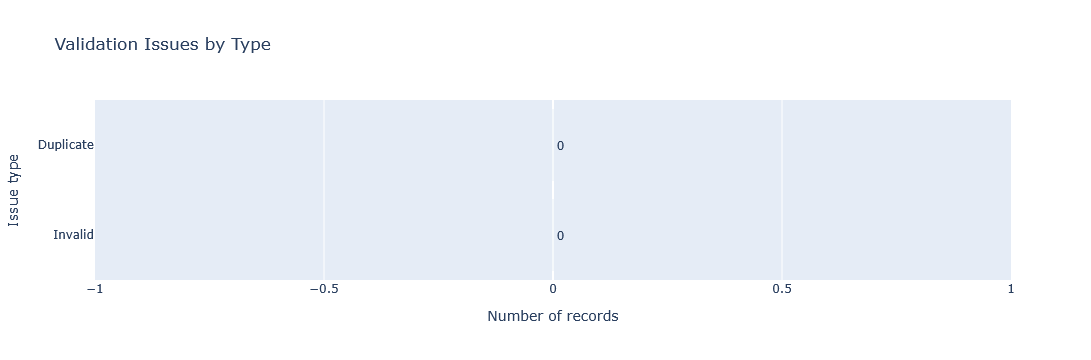

KeyError: 'completeness_pct'

In [10]:
if validation_report is not None:
    issue_candidates = ["missing", "invalid", "duplicate"]
    issue_counts = {}
    for issue in issue_candidates:
        value = find_value(validation_report, [
            issue, f"{issue}_records", f"{issue}_count"
        ])
        if value is not None:
            issue_counts[issue.title()] = value

    if issue_counts:
        issue_df = pd.DataFrame(
            list(issue_counts.items()), columns=["Issue type", "Records"]
        ).sort_values("Records", ascending=True)
        fig = px.bar(
            issue_df, x="Records", y="Issue type", orientation="h",
            text="Records", title="Validation Issues by Type",
            labels={"Records": "Number of records"}
        )
        fig.update_traces(textposition="outside")
        fig.show()
    else:
        print("Issue-type counts were not recognized automatically; inspect the raw validation report above.")

completeness = (
    df.replace({"": np.nan, "Unknown": np.nan})
      .notna().mean().mul(100)
      .sort_values()
      .rename("completeness_pct")
      .reset_index()
)
completeness.columns = ["Field", "Completeness (%)"]

fig = px.bar(
    completeness,
    x="completeness_pct",
    y="Field",
    orientation="h",
    text=completeness["completeness_pct"].map(lambda value: f"{value:.1f}%"),
    title="Field Completeness in Validated Database Records",
    labels={"completeness_pct": "Completeness (%)", "Field": "Field"}
)
fig.update_xaxes(range=[0, 100])
fig.update_traces(textposition="outside")
fig.show()

display(completeness.sort_values("Completeness (%)"))

# Research Question 6 — Providers with the highest recorded success rates

**Question:** Which providers have the highest recorded success rates among launches with known final outcomes?

Success rate is calculated as:

\[
\text{Success Rate} = \frac{\text{Successful launches}}{\text{Successful + failed + partial-failure launches}} \times 100
\]

Pending, unknown, and other non-final statuses are excluded from the denominator. A minimum launch-count threshold is used to avoid ranking providers based on very small samples.

In [ ]:
FINAL_SUCCESS = "Launch Successful"
FINAL_FAILURE = "Launch Failure"
FINAL_PARTIAL_FAILURE = "Launch was a Partial Failure"
FINAL_STATUSES = {FINAL_SUCCESS, FINAL_FAILURE, FINAL_PARTIAL_FAILURE}

final_outcomes = df[df["status"].isin(FINAL_STATUSES)].copy()

provider_performance = (
    final_outcomes.assign(is_success=final_outcomes["status"].eq(FINAL_SUCCESS))
    .groupby("provider")
    .agg(
        known_final_launches=("launch_id", "count"),
        successful_launches=("is_success", "sum")
    )
    .reset_index()
)

provider_performance["success_rate_pct"] = (
    provider_performance["successful_launches"]
    / provider_performance["known_final_launches"] * 100
)

# Adjust this threshold if your report requires a different minimum sample size.
MIN_FINAL_LAUNCHES = 5

ranked_providers = (
    provider_performance[
        provider_performance["known_final_launches"] >= MIN_FINAL_LAUNCHES
    ]
    .sort_values("success_rate_pct", ascending=True)
)

if ranked_providers.empty:
    print(
        f"No provider has at least {MIN_FINAL_LAUNCHES} launches with known final outcomes. "
        "Lower MIN_FINAL_LAUNCHES if you want to inspect smaller samples."
    )
else:
    fig = px.bar(
        ranked_providers,
        x="success_rate_pct",
        y="provider",
        orientation="h",
        text=ranked_providers.apply(
            lambda row: f'{row["success_rate_pct"]:.1f}% (n={int(row["known_final_launches"])})',
            axis=1
        ),
        title=f"Provider Success Rates (Minimum {MIN_FINAL_LAUNCHES} Final Outcomes)",
        labels={
            "success_rate_pct": "Success rate (%)",
            "provider": "Provider"
        },
        hover_data={
            "successful_launches": True,
            "known_final_launches": True,
            "success_rate_pct": ":.2f"
        }
    )
    fig.update_xaxes(range=[0, 100])
    fig.update_traces(textposition="outside")
    fig.show()

display(provider_performance.sort_values("success_rate_pct", ascending=False))

## 10. Key findings and interpretation

Use the outputs above to write findings based on the actual dataset. Do not assume that a larger number of recorded launches means a higher success rate, and do not interpret missing or pending outcomes as failures.

Suggested points to discuss in your project presentation:
- Which year had the most recorded launches?
- Which months appear busiest across the available years?
- Which providers, rocket configurations, and launch locations occur most often?
- Do outcome distributions differ across providers or years?
- Which providers have the highest success rates after applying the minimum sample threshold?
- What are the most common validation issues?

## Notes and limitations

1. All launch-activity and outcome charts use the validated SQLite dataset.
2. Q5 requires the separate validation report and cannot be fully reconstructed from the valid-only database.
3. Success-rate calculations include only the three final outcome statuses: successful, failure, and partial failure.
4. Pending and other non-final statuses are not counted as failures.
5. The notebook is read-only with respect to SQLite; it does not change the database.
6. The chart outputs depend on the records actually present. If the database currently contains only a small test extraction, the charts will reflect that limited sample.